# FCSS Practical Tutorial: DataFrames and Social-Media Data Analysis

By the end, you should be able to load a CSV with pandas, inspect a DataFrame, select columns, filter rows, create a new column, calculate simple summaries, and make one simple plot.

## 1. Load the data
Last time we processed lists of dictionaries. Today pandas gives us a table-like structure called a DataFrame.

In [5]:
import pandas as pd

df = pd.read_csv("social_media_posts.csv")
df

,post_id,platform,text,likes,comments
0,P01,Forum,Bus service was good today,8,2
1,P02,Forum,The tram was delayed again this morning,15,6
2,P03,X,More cycling lanes would improve the city,21,5
3,P04,Forum,Walking to campus is usually convenient,6,1
4,P05,X,Public transport is getting better,12,3
5,P06,Forum,Traffic around campus was terrible today,18,7
6,P07,X,The train connection saves me time,9,2
7,P08,Forum,More buses are needed during rush hour,24,8


### Mini-task 1
Display the first 5 rows, the column names, and the DataFrame shape.

Useful tools: `df.head()`, `df.columns`, `df.shape`.

In [6]:
print(df.head())
print(df.columns)
print(df.shape)

  post_id platform                                       text  likes  comments
0     P01    Forum                 Bus service was good today      8         2
1     P02    Forum    The tram was delayed again this morning     15         6
2     P03        X  More cycling lanes would improve the city     21         5
3     P04    Forum    Walking to campus is usually convenient      6         1
4     P05        X         Public transport is getting better     12         3
Index(['post_id', 'platform', 'text', 'likes', 'comments'], dtype='str')
(8, 5)


## 2. Select columns
One column: `df["likes"]`

Several columns: `df[["post_id", "likes"]]`

In [7]:
df["likes"]

0     8
1    15
2    21
3     6
4    12
5    18
6     9
7    24
Name: likes, dtype: int64

### Mini-task 2
Display only `post_id`, `platform`, and `likes`.

In [8]:
df[["post_id","platform","likes"]]

,post_id,platform,likes
0,P01,Forum,8
1,P02,Forum,15
2,P03,X,21
3,P04,Forum,6
4,P05,X,12
5,P06,Forum,18
6,P07,X,9
7,P08,Forum,24


## 3. Filter rows
Filtering keeps only rows that satisfy a condition.

In [9]:
popular = df[df["likes"] >= 15]
popular

,post_id,platform,text,likes,comments
1,P02,Forum,The tram was delayed again this morning,15,6
2,P03,X,More cycling lanes would improve the city,21,5
5,P06,Forum,Traffic around campus was terrible today,18,7
7,P08,Forum,More buses are needed during rush hour,24,8


### Mini-task 3
Find posts with fewer than 10 likes. Display only `post_id` and `likes`.

In [10]:
df[df["likes"] < 10][["post_id","likes"]]

,post_id,likes
0,P01,8
3,P04,6
6,P07,9


## 4. Combine conditions
Use `&` for AND and put each condition in parentheses.

In [11]:
forum_popular = df[(df["platform"] == "Forum") & (df["likes"] >= 15)]
forum_popular

,post_id,platform,text,likes,comments
1,P02,Forum,The tram was delayed again this morning,15,6
5,P06,Forum,Traffic around campus was terrible today,18,7
7,P08,Forum,More buses are needed during rush hour,24,8


### Mini-task 4
Find posts from `X` with at least 10 likes. Display `post_id`, `likes`, and `comments`.

In [12]:
x_posts=df[(df["platform"]=="X") & (df["likes"]>=10)]
x_posts[["post_id","likes","comments"]]

,post_id,likes,comments
2,P03,21,5
4,P05,12,3


## 5. Create a new column
We will create a simple classroom engagement measure: `likes + comments`.

In [13]:
df["engagement"] = df["likes"] + df["comments"]
df[["post_id","likes","comments","engagement"]]

,post_id,likes,comments,engagement
0,P01,8,2,10
1,P02,15,6,21
2,P03,21,5,26
3,P04,6,1,7
4,P05,12,3,15
5,P06,18,7,25
6,P07,9,2,11
7,P08,24,8,32


### Mini-task 5
Create `word_count` using:

`df["text"].str.split().str.len()`

Then display `post_id` and `word_count`.

In [14]:
df["word_count"]=df["text"].str.split().str.len()
df[["post_id","word_count"]]

,post_id,word_count
0,P01,5
1,P02,7
2,P03,7
3,P04,6
4,P05,5
5,P06,6
6,P07,6
7,P08,7


## 6. Simple summaries

In [15]:
print("Average likes:", df["likes"].mean())
print("Maximum likes:", df["likes"].max())
print("Average comments:", df["comments"].mean())

Average likes: 14.125
Maximum likes: 24
Average comments: 4.25


### Mini-task 6
Calculate the minimum likes, average engagement, and the row with the highest engagement.

Hint: `df.loc[df["engagement"].idxmax()]`

In [16]:
print("Minimum likes:",df["likes"].min())
print("Average engagement:",df["engagement"].mean())
print(df.loc[df["engagement"].idxmax()])

Minimum likes: 6
Average engagement: 18.375
post_id                                          P08
platform                                       Forum
text          More buses are needed during rush hour
likes                                             24
comments                                           8
engagement                                        32
word_count                                         7
Name: 7, dtype: object


## 7. Group by platform
`groupby()` lets us calculate summaries separately for each category.

In [17]:
df.groupby("platform")[["likes","comments"]].mean()

,likes,comments
platform,,
Forum,14.2,4.800000
X,14.0,3.333333


### Mini-task 7
Calculate average engagement for each platform.

In [18]:
df.groupby("platform")["engagement"].mean()

platform
Forum    19.000000
X        17.333333
Name: engagement, dtype: float64

## 8. Simple plot

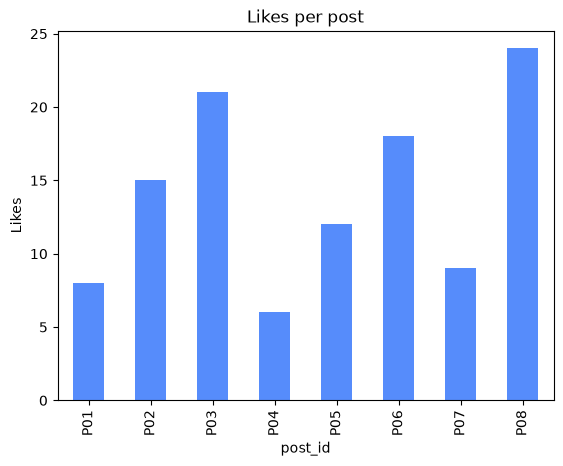

In [19]:
import matplotlib.pyplot as plt

df.plot(x="post_id",y="likes",kind="bar",legend=False)
plt.ylabel("Likes")
plt.title("Likes per post")
plt.show()

### Mini-task 8
Create a bar chart showing `engagement` for each `post_id`. Add a title and y-axis label.

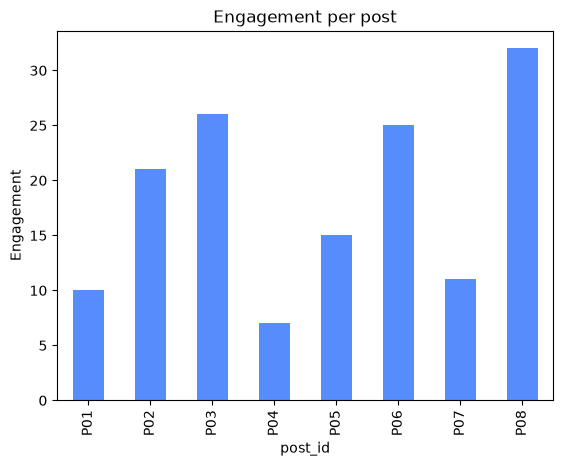

In [20]:
df.plot(x="post_id",y="engagement",kind="bar",legend=False)
plt.ylabel("Engagement")
plt.title("Engagement per post")
plt.show()

## 9. Combined challenge
Find posts with at least 15 likes and at least 5 comments. Display `post_id`, `platform`, `likes`, `comments`, and `engagement`. Then answer: how many match, and which platform appears most often?

In [21]:
selected=df[(df["likes"]>=15) & (df["comments"]>=5)]
result=selected[["post_id","platform","likes","comments","engagement"]]
print(result)
print("Number:",len(result))
print("Most common platform:",selected["platform"].mode()[0])

  post_id platform  likes  comments  engagement
1     P02    Forum     15         6          21
2     P03        X     21         5          26
5     P06    Forum     18         7          25
7     P08    Forum     24         8          32
Number: 4
Most common platform: Forum


## 10. Exit check
1. What is a DataFrame?
2. What is the difference between selecting columns and filtering rows?
3. What does `df.shape` tell us?
4. Why do pandas filters use `&` for AND?
5. Why might we create a derived column such as `engagement`?

These skills will be useful for larger social-media datasets and the sentiment-analysis assignment.

## Common errors

Wrong brackets for multiple columns, using `and` instead of `&`, missing parentheses, misspelled column names, and running cells out of order.